# CA1 LFP band power with MNE filters (Dandiset 001695)

Builds band-pass FIR filters with MNE, applies them to the session's single CA1 LFP channel
(`Best_Ripple_channel_LFP_CA1`, about 1250 Hz), takes the Hilbert envelope and bins the band power.
The result is a small table (one row per bin, one column per band) written to storage, which the
Grassmannian notebook (`../Hp_grassmannian_pipeline_001695.ipynb`) reads to colour its windows.
It also pulls the scored sleep states out of the file (pynapple drops those labels) and saves them
next to the band-power table.

* kernel: `hydrangea_lfp_mne_env`; create it on the server with
  `bash conda_and_jupyterkernel_lfp_mne.sh` (this folder)
* the FIR filters are saved beside this notebook in `filters/` (taps + band definitions), so the
  Grassmannian notebook never needs MNE
* outputs: `storage/grassmanian_test/Hp_001695/lfp/bandpower_<session>.npz` and
  `sleepstates_<session>.csv` (derived data that saves re-filtering; figures are only displayed)

In [1]:
# ============ storage: same roots as the Grassmannian notebook, one folder deeper ============
from pathlib import Path

STORAGE_DIR   = Path("../../../storage").resolve()
DOWNLOAD_DIR  = STORAGE_DIR / "dandi_downloads"                            # INPUTS (NWB files)
DATASET_LABEL = "Hp_001695"
LFP_OUT_DIR   = STORAGE_DIR / "grassmanian_test" / DATASET_LABEL / "lfp"   # band-power tables, sleep states
FILTER_DIR    = Path("filters").resolve()                                   # FIR filters live in the repo, beside this notebook
LFP_OUT_DIR.mkdir(parents=True, exist_ok=True)
FILTER_DIR.mkdir(parents=True, exist_ok=True)
print("inputs :", DOWNLOAD_DIR)
print("filters:", FILTER_DIR)
print("outputs:", LFP_OUT_DIR)

inputs : /notebooks/CumulantDynamicsGuiltByAssociation/Hydrangea_demo/Validating_Hybrid_Dynamics/storage/dandi_downloads
filters: /notebooks/CumulantDynamicsGuiltByAssociation/Hydrangea_demo/Validating_Hybrid_Dynamics/RealData_Grassmanian_Tests/CA1data/lfp_filters/filters
outputs: /notebooks/CumulantDynamicsGuiltByAssociation/Hydrangea_demo/Validating_Hybrid_Dynamics/storage/grassmanian_test/Hp_001695/lfp


In [4]:
# ============ config ============
import json, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sps
import mne
import pynapple as nap

SESSION_FILE = DOWNLOAD_DIR / "sub-M01" / "sub-M01_ses-20240313T100000_behavior+ecephys.nwb"   # same session as the Grassmannian notebook
LFP_KEY      = "Best_Ripple_channel_LFP_CA1"      # the one LFP channel in the file (pynapple key)
BIN_MS       = 50.0                               # band power is averaged in bins of this length
BANDS = {                                          # Hz, mouse hippocampus
    "delta":      (1.0,   4.0),
    "theta":      (6.0,  12.0),
    "beta":      (15.0,  30.0),
    "slow_gamma": (30.0,  55.0),
    "fast_gamma": (65.0, 100.0),
    "ripple":   (130.0, 250.0),
}
FIR = dict(method="fir", fir_design="firwin", fir_window="hamming", phase="zero",
           l_trans_bandwidth="auto", h_trans_bandwidth="auto", filter_length="auto")


def session_key_from_path(path):
    sub = re.search(r"sub-([^_/]+)", str(path))
    ses = re.search(r"ses-([^_/]+)", str(path))
    return "%s_%s" % (sub.group(1), ses.group(1)) if (sub and ses) else Path(path).stem


SESSION_KEY = session_key_from_path(SESSION_FILE)
print("session:", SESSION_KEY, "| mne", mne.__version__)

session: M01_20240313T100000 | mne 1.13.2


In [6]:
# ============ storage: find the root that actually holds the downloaded session ============
from pathlib import Path

SESSION_REL = Path("dandi_downloads/sub-M01/sub-M01_ses-20240313T100000_behavior+ecephys.nwb")
STORAGE_DIR_OVERRIDE = None     # e.g. Path("/storage"); copy the "inputs :" line printed by the Hp notebook's first cell

candidates = ([Path(STORAGE_DIR_OVERRIDE)] if STORAGE_DIR_OVERRIDE else []) + [
    Path("../../../storage"), Path("../../storage"), Path("../../../../storage"),
    Path("/storage"), Path.home() / "storage",
]
found = [c.resolve() for c in candidates if (c / SESSION_REL).exists()]
if not found:
    raise FileNotFoundError(
        "session file not found under any of:\n  " + "\n  ".join(str(c.resolve()) for c in candidates)
        + "\nSet STORAGE_DIR_OVERRIDE to the storage root the Hp notebook printed as 'inputs :' (minus /dandi_downloads).")
STORAGE_DIR   = found[0]
DOWNLOAD_DIR  = STORAGE_DIR / "dandi_downloads"                            # INPUTS (NWB files)
DATASET_LABEL = "Hp_001695"
LFP_OUT_DIR   = STORAGE_DIR / "grassmanian_test" / DATASET_LABEL / "lfp"   # band-power tables, sleep states
FILTER_DIR    = Path("filters").resolve()                                   # FIR filters live in the repo, beside this notebook
LFP_OUT_DIR.mkdir(parents=True, exist_ok=True)
FILTER_DIR.mkdir(parents=True, exist_ok=True)
print("storage:", STORAGE_DIR, "(other roots checked: %d)" % (len(candidates) - 1))
print("inputs :", DOWNLOAD_DIR)
print("filters:", FILTER_DIR)
print("outputs:", LFP_OUT_DIR)


storage: /storage (other roots checked: 4)
inputs : /storage/dandi_downloads
filters: /notebooks/CumulantDynamicsGuiltByAssociation/Hydrangea_demo/Validating_Hybrid_Dynamics/RealData_Grassmanian_Tests/CA1data/lfp_filters/filters
outputs: /storage/grassmanian_test/Hp_001695/lfp


In [7]:
# ============ scored sleep states: pynapple drops the labels, pynwb keeps them ============
import pynwb

sleep_states = None
try:
    with pynwb.NWBHDF5IO(str(SESSION_FILE), "r", load_namespaces=True) as io:
        nwbfile = io.read()
        if "SleepStates" in nwbfile.intervals:
            ss = nwbfile.intervals["SleepStates"].to_dataframe().reset_index(drop=True)
            label_cols = [c for c in ss.columns if c not in ("start_time", "stop_time", "tags", "timeseries")]
            print("SleepStates columns:", list(ss.columns))
            if label_cols:
                sleep_states = (ss[["start_time", "stop_time", label_cols[0]]]
                                .rename(columns={label_cols[0]: "state"}))
                sleep_states["state"] = sleep_states["state"].astype(str)
                print("using %r as the state label:" % label_cols[0])
                print(sleep_states.groupby("state").apply(
                    lambda g: pd.Series({"intervals": len(g), "seconds": (g.stop_time - g.start_time).sum()})))
                sleep_states.to_csv(LFP_OUT_DIR / ("sleepstates_%s.csv" % SESSION_KEY), index=False)
                print("wrote", LFP_OUT_DIR / ("sleepstates_%s.csv" % SESSION_KEY))
            else:
                print("SleepStates has no label column; nothing written")
        else:
            print("no SleepStates interval table in the file")
except Exception as exc:
    print("could not read SleepStates with pynwb:", repr(exc))

could not read SleepStates with pynwb: FileNotFoundError(2, "Unable to synchronously open file (unable to open file: name = '/notebooks/CumulantDynamicsGuiltByAssociation/Hydrangea_demo/Validating_Hybrid_Dynamics/storage/dandi_downloads/sub-M01/sub-M01_ses-20240313T100000_behavior+ecephys.nwb', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)")


,pass_hz,stop_edges_hz,taps,length_s,passband_ripple_db_inner80,stopband_max_db
band,,,,,,
delta,1-4,0.5 | 5,12501,10.00,0.0,-60.62
theta,6-12,4.5 | 14,4167,3.33,0.0,-60.68
beta,15-30,12 | 34,2085,1.67,0.0,-60.26
slow_gamma,30-55,25 | 59,1563,1.25,0.0,-60.30
fast_gamma,66-100,61 | 110,1251,1.00,0.0,-59.92
ripple,130-250,115 | 275,417,0.33,0.0,-59.90


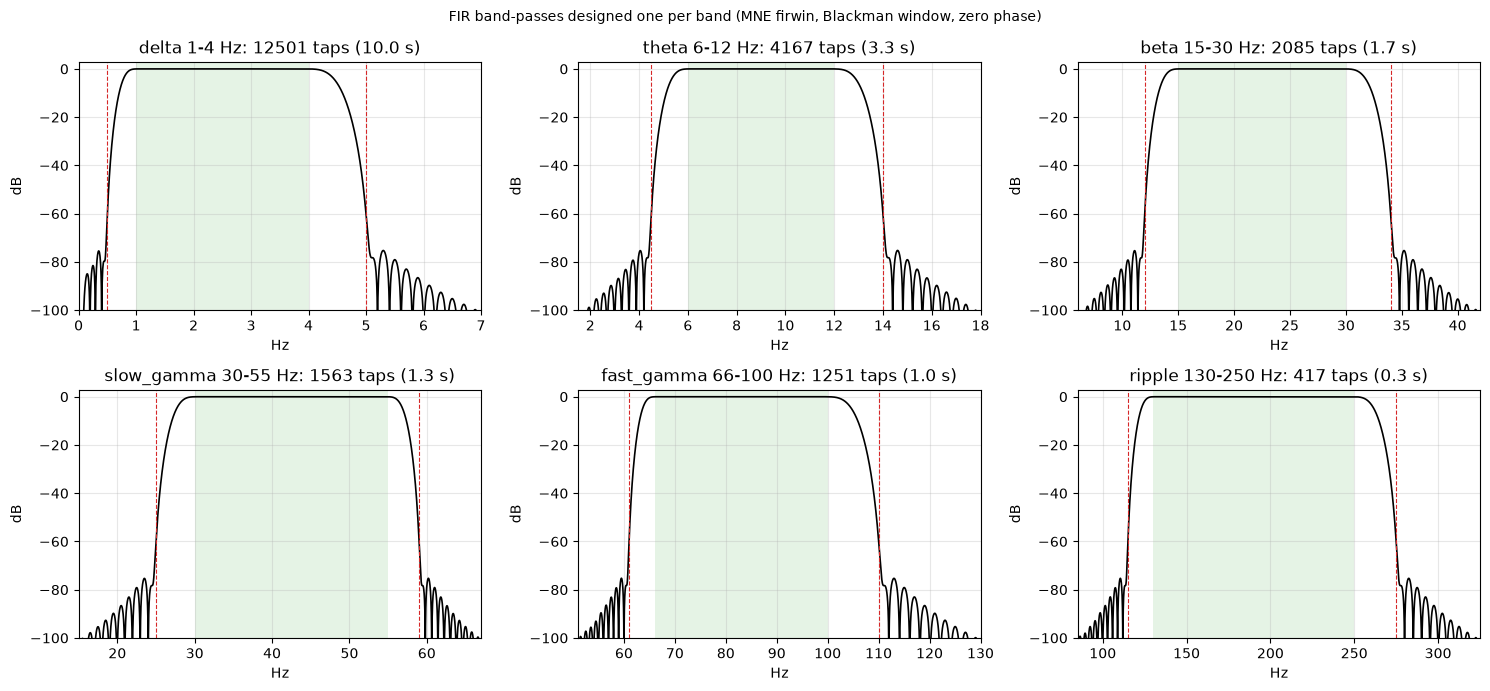

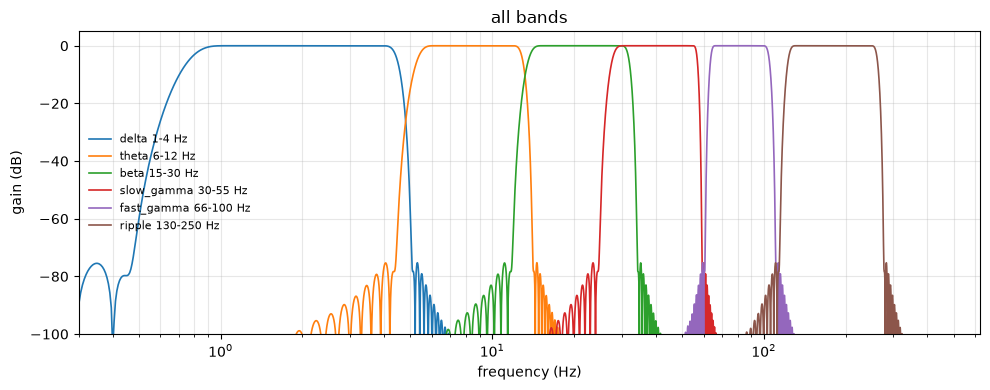

In [13]:
# ============ design the band-pass FIR filters with MNE, band by band; store them beside this notebook ============
fs = 1250.0

# per band: pass-band edges and the width of each transition band (Hz). MNE's firwin puts the pass-band edge
# at lo / hi and the stop-band edge at lo - l_trans / hi + h_trans (-6 dB half-way between). Blackman window:
# ~74 dB stop-band attenuation; filter length = 5 / min(transition) s, so a narrow transition = a long filter.
BAND_DESIGN = {
    #  name           lo      hi   l_trans  h_trans
    "delta":      (  1.0,   4.0,    0.5,     1.0),
    "theta":      (  6.0,  12.0,    1.5,     2.0),
    "beta":       ( 15.0,  30.0,    3.0,     4.0),
    "slow_gamma": ( 30.0,  55.0,    5.0,     4.0),
    "fast_gamma": ( 66.0, 100.0,    5.0,    10.0), 
    "ripple":     (130.0, 250.0,   15.0,    25.0),
}
BANDS = {k: (v[0], v[1]) for k, v in BAND_DESIGN.items()}      # the later cells use BANDS
FIR = dict(method="fir", fir_design="firwin", fir_window="blackman", phase="zero", filter_length="auto")

filters, rows = {}, []
for name, (lo, hi, lt, ht) in BAND_DESIGN.items():
    taps = np.asarray(mne.filter.create_filter(None, fs, l_freq=lo, h_freq=hi, l_trans_bandwidth=lt,
                                               h_trans_bandwidth=ht, verbose=False, **FIR), dtype=float)
    filters[name] = taps
    w, h = sps.freqz(taps, worN=2 ** 17, fs=fs)
    g = 20 * np.log10(np.abs(h) + 1e-12)
    inner = (w >= lo + 0.1 * (hi - lo)) & (w <= hi - 0.1 * (hi - lo))
    stop = (w <= lo - lt) | (w >= hi + ht)
    rows.append({"band": name, "pass_hz": "%g-%g" % (lo, hi), "stop_edges_hz": "%g | %g" % (lo - lt, hi + ht),
                 "taps": len(taps), "length_s": len(taps) / fs,
                 "passband_ripple_db_inner80": g[inner].max() - g[inner].min(),
                 "stopband_max_db": g[stop].max()})
    np.savez(FILTER_DIR / ("fir_%s_%.0fHz.npz" % (name, fs)), taps=taps, l_freq=lo, h_freq=hi,
             l_trans=lt, h_trans=ht, fs=fs, design=json.dumps(FIR))
(FILTER_DIR / "bands.json").write_text(json.dumps({"fs": fs, "bands": BAND_DESIGN, "fir": FIR, "lfp_key": LFP_KEY}, indent=2))
display(pd.DataFrame(rows).set_index("band").round(2))

# one panel per band, linear axis around the band: green = pass band, red dashed = stop-band edges
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (name, (lo, hi, lt, ht)) in zip(axes.ravel(), BAND_DESIGN.items()):
    w, h = sps.freqz(filters[name], worN=2 ** 17, fs=fs)
    ax.plot(w, 20 * np.log10(np.abs(h) + 1e-12), lw=1.2, color="k")
    ax.axvspan(lo, hi, color="tab:green", alpha=0.12, lw=0)
    for x in (lo - lt, hi + ht):
        ax.axvline(x, color="tab:red", lw=0.8, ls="--")
    ax.set(xlim=(max(0, lo - 3 * lt), hi + 3 * ht), ylim=(-100, 3), xlabel="Hz", ylabel="dB",
           title="%s %g-%g Hz: %d taps (%.1f s)" % (name, lo, hi, len(filters[name]), len(filters[name]) / fs))
    ax.grid(alpha=0.3)
fig.suptitle("FIR band-passes designed one per band (MNE firwin, Blackman window, zero phase)", fontsize=10)
plt.tight_layout(); plt.show()

# all bands together on a log axis
fig, ax = plt.subplots(figsize=(10, 4))
for name, taps in filters.items():
    w, h = sps.freqz(taps, worN=2 ** 17, fs=fs)
    ax.plot(w, 20 * np.log10(np.abs(h) + 1e-12), lw=1.2, label="%s %g-%g Hz" % (name, *BANDS[name]))
ax.set(xscale="log", xlim=(0.3, fs / 2), ylim=(-100, 5), xlabel="frequency (Hz)", ylabel="gain (dB)", title="all bands")
ax.legend(fontsize=8, frameon=False); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()


In [19]:
# ============ apply the stored filters, Hilbert envelope, bin the power; one file per band ============
import time, json
import numpy as np
import scipy.signal as sps
import pynapple as nap
from pathlib import Path
from scipy.fft import next_fast_len

LFP_FILE    = Path("/storage/dandi_downloads/sub-M01/sub-M01_ses-20240313T100000_behavior+ecephys.nwb")
LFP_KEY     = "Best_Ripple_channel_LFP_CA1"
OUT_DIR     = Path("/storage/grassmanian_test/Hp_001695/lfp")
SESSION_KEY = "M01_20240313T100000"
fs          = 1250.0
BIN_MS      = 50.0
OUT_DIR.mkdir(parents=True, exist_ok=True)

x_lfp = np.asarray(nap.load_file(str(LFP_FILE))[LFP_KEY].values, dtype=float).reshape(-1)
t_lfp = np.arange(len(x_lfp)) / fs                                   # session seconds; the LFP starts at t = 0
print("LFP: %d samples, %.1f s at %g Hz" % (len(x_lfp), t_lfp[-1], fs))

bin_s = BIN_MS / 1000.0
bin_idx = np.floor(t_lfp / bin_s).astype(np.int64)
n_bins = int(bin_idx.max()) + 1
n_per_bin = np.bincount(bin_idx, minlength=n_bins).astype(float)
t_center = (np.arange(n_bins) + 0.5) * bin_s
nfft = next_fast_len(len(x_lfp))

for name, taps in filters.items():
    t_b = time.time()
    xf = sps.oaconvolve(x_lfp, taps, mode="same")                   # zero phase: symmetric taps, centred output
    env2 = np.abs(sps.hilbert(xf, N=nfft)[:len(xf)]) ** 2           # squared Hilbert envelope = instantaneous power
    p = (np.bincount(bin_idx, weights=env2, minlength=n_bins) / np.maximum(n_per_bin, 1)).astype(np.float32)
    del xf, env2
    out = OUT_DIR / ("bandpower_%s_%s.npz" % (SESSION_KEY, name))
    np.savez_compressed(out, power=p, t_center=t_center, band=name, n_taps=len(taps), fs=fs, bin_ms=BIN_MS,
                        lfp_key=LFP_KEY, session=SESSION_KEY)
    print("%-11s done in %5.1fs | median power %.3g | %d taps | %s" % (name, time.time() - t_b, np.median(p), len(taps), out.name))


LFP: 13985972 samples, 11188.8 s at 1250 Hz
delta       done in   7.2s | median power 3.1e-05 | 12501 taps | bandpower_M01_20240313T100000_delta.npz
theta       done in   6.6s | median power 2.4e-07 | 4167 taps | bandpower_M01_20240313T100000_theta.npz
beta        done in   6.4s | median power 3.25e-08 | 2085 taps | bandpower_M01_20240313T100000_beta.npz
slow_gamma  done in   6.4s | median power 6.18e-09 | 1563 taps | bandpower_M01_20240313T100000_slow_gamma.npz
fast_gamma  done in   7.0s | median power 6.77e-10 | 1251 taps | bandpower_M01_20240313T100000_fast_gamma.npz
ripple      done in   6.3s | median power 3.57e-10 | 417 taps | bandpower_M01_20240313T100000_ripple.npz


In [21]:
# ============ load the saved filters from disk, cut by the longest, apply: Hilbert-envelope power per bin ============
import time, json
import numpy as np
import scipy.signal as sps
import pynapple as nap
from pathlib import Path
from scipy.fft import next_fast_len

FILTER_DIR  = Path("filters").resolve()                              # where the design cell saved fir_<band>_1250Hz.npz
LFP_FILE    = Path("/storage/dandi_downloads/sub-M01/sub-M01_ses-20240313T100000_behavior+ecephys.nwb")
LFP_KEY     = "Best_Ripple_channel_LFP_CA1"
OUT_DIR     = Path("/storage/grassmanian_test/Hp_001695/lfp")
SESSION_KEY = "M01_20240313T100000"
fs          = 1250.0
BIN_MS      = 50.0

# ---- the filters, one file each, different lengths
filters, BAND_DESIGN = {}, {}
for f in sorted(FILTER_DIR.glob("fir_*_%.0fHz.npz" % fs)):
    with np.load(f) as z:
        name = f.stem[len("fir_"):-len("_%.0fHz" % fs)]
        filters[name] = z["taps"].astype(float)
        BAND_DESIGN[name] = (float(z["l_freq"]), float(z["h_freq"]), float(z["l_trans"]), float(z["h_trans"]))
if not filters:
    raise FileNotFoundError("no fir_*_%.0fHz.npz in %s" % (fs, FILTER_DIR))
longest_band = max(filters, key=lambda b: len(filters[b]))
cut_margin_s = (len(filters[longest_band]) // 2) / fs
print("filters loaded:", {b: len(t) for b, t in filters.items()})
print("longest: %s -> cut %.1f s off each end of the recording" % (longest_band, cut_margin_s))

# ---- the recording
x_lfp = np.asarray(nap.load_file(str(LFP_FILE))[LFP_KEY].values, dtype=float).reshape(-1)
t_lfp = np.arange(len(x_lfp)) / fs                                   # session seconds; the LFP starts at t = 0
cut_start_s, cut_end_s = cut_margin_s, t_lfp[-1] - cut_margin_s
print("LFP: %d samples, %.1f s at %g Hz; trusted range %.1f .. %.1f s" % (len(x_lfp), t_lfp[-1], fs, cut_start_s, cut_end_s))

# ---- filter the full recording (so the cut falls where the longest filter says), bin the power
bin_s = BIN_MS / 1000.0
bin_idx = np.floor(t_lfp / bin_s).astype(np.int64)
n_bins = int(bin_idx.max()) + 1
n_per_bin = np.bincount(bin_idx, minlength=n_bins).astype(float)
t_center = (np.arange(n_bins) + 0.5) * bin_s
bins_in_cut = (t_center >= cut_start_s) & (t_center <= cut_end_s)
nfft = next_fast_len(len(x_lfp))

powers = {}                                                          # band -> power per bin, full length
for name, taps in filters.items():
    t_b = time.time()
    xf = sps.oaconvolve(x_lfp, taps, mode="same")                   # zero phase: symmetric taps, centred output
    env2 = np.abs(sps.hilbert(xf, N=nfft)[:len(xf)]) ** 2           # squared Hilbert envelope = instantaneous power
    powers[name] = (np.bincount(bin_idx, weights=env2, minlength=n_bins) / np.maximum(n_per_bin, 1)).astype(np.float32)
    del xf, env2
    print("%-11s done in %5.1fs | median power in the cut %.3g" % (name, time.time() - t_b, np.median(powers[name][bins_in_cut])))
print("bands:", list(powers), "| %d bins at %g ms, %d inside the cut" % (n_bins, BIN_MS, int(bins_in_cut.sum())))


filters loaded: {'beta': 2085, 'delta': 12501, 'fast_gamma': 1251, 'ripple': 417, 'slow_gamma': 1563, 'theta': 4167}
longest: delta -> cut 5.0 s off each end of the recording
LFP: 13985972 samples, 11188.8 s at 1250 Hz; trusted range 5.0 .. 11183.8 s
beta        done in   6.3s | median power in the cut 3.23e-08
delta       done in   6.4s | median power in the cut 3.06e-05
fast_gamma  done in   6.0s | median power in the cut 6.7e-10
ripple      done in   6.8s | median power in the cut 3.54e-10
slow_gamma  done in   6.6s | median power in the cut 6.12e-09
theta       done in   6.4s | median power in the cut 2.39e-07
bands: ['beta', 'delta', 'fast_gamma', 'ripple', 'slow_gamma', 'theta'] | 223776 bins at 50 ms, 223576 inside the cut


filters: {'beta': 2085, 'delta': 12501, 'fast_gamma': 1251, 'ripple': 417, 'slow_gamma': 1563, 'theta': 4167} | longest delta -> 5.0 s cut from each end of every live stretch
LFP: 11188.8 s, 37.8% live, 37 live stretches, 36 usable after the cut (dropping 1 short ones)
done in 2.6s | trusted signal 64.4 min | bins with power: 77240 of 223776
beta        median power 4.6e+03
delta       median power 2.17e+04
fast_gamma  median power 945
ripple      median power 554
slow_gamma  median power 2.4e+03
theta       median power 1.77e+04
raw 10 s at 3000 s: std 203, 1098 unique values


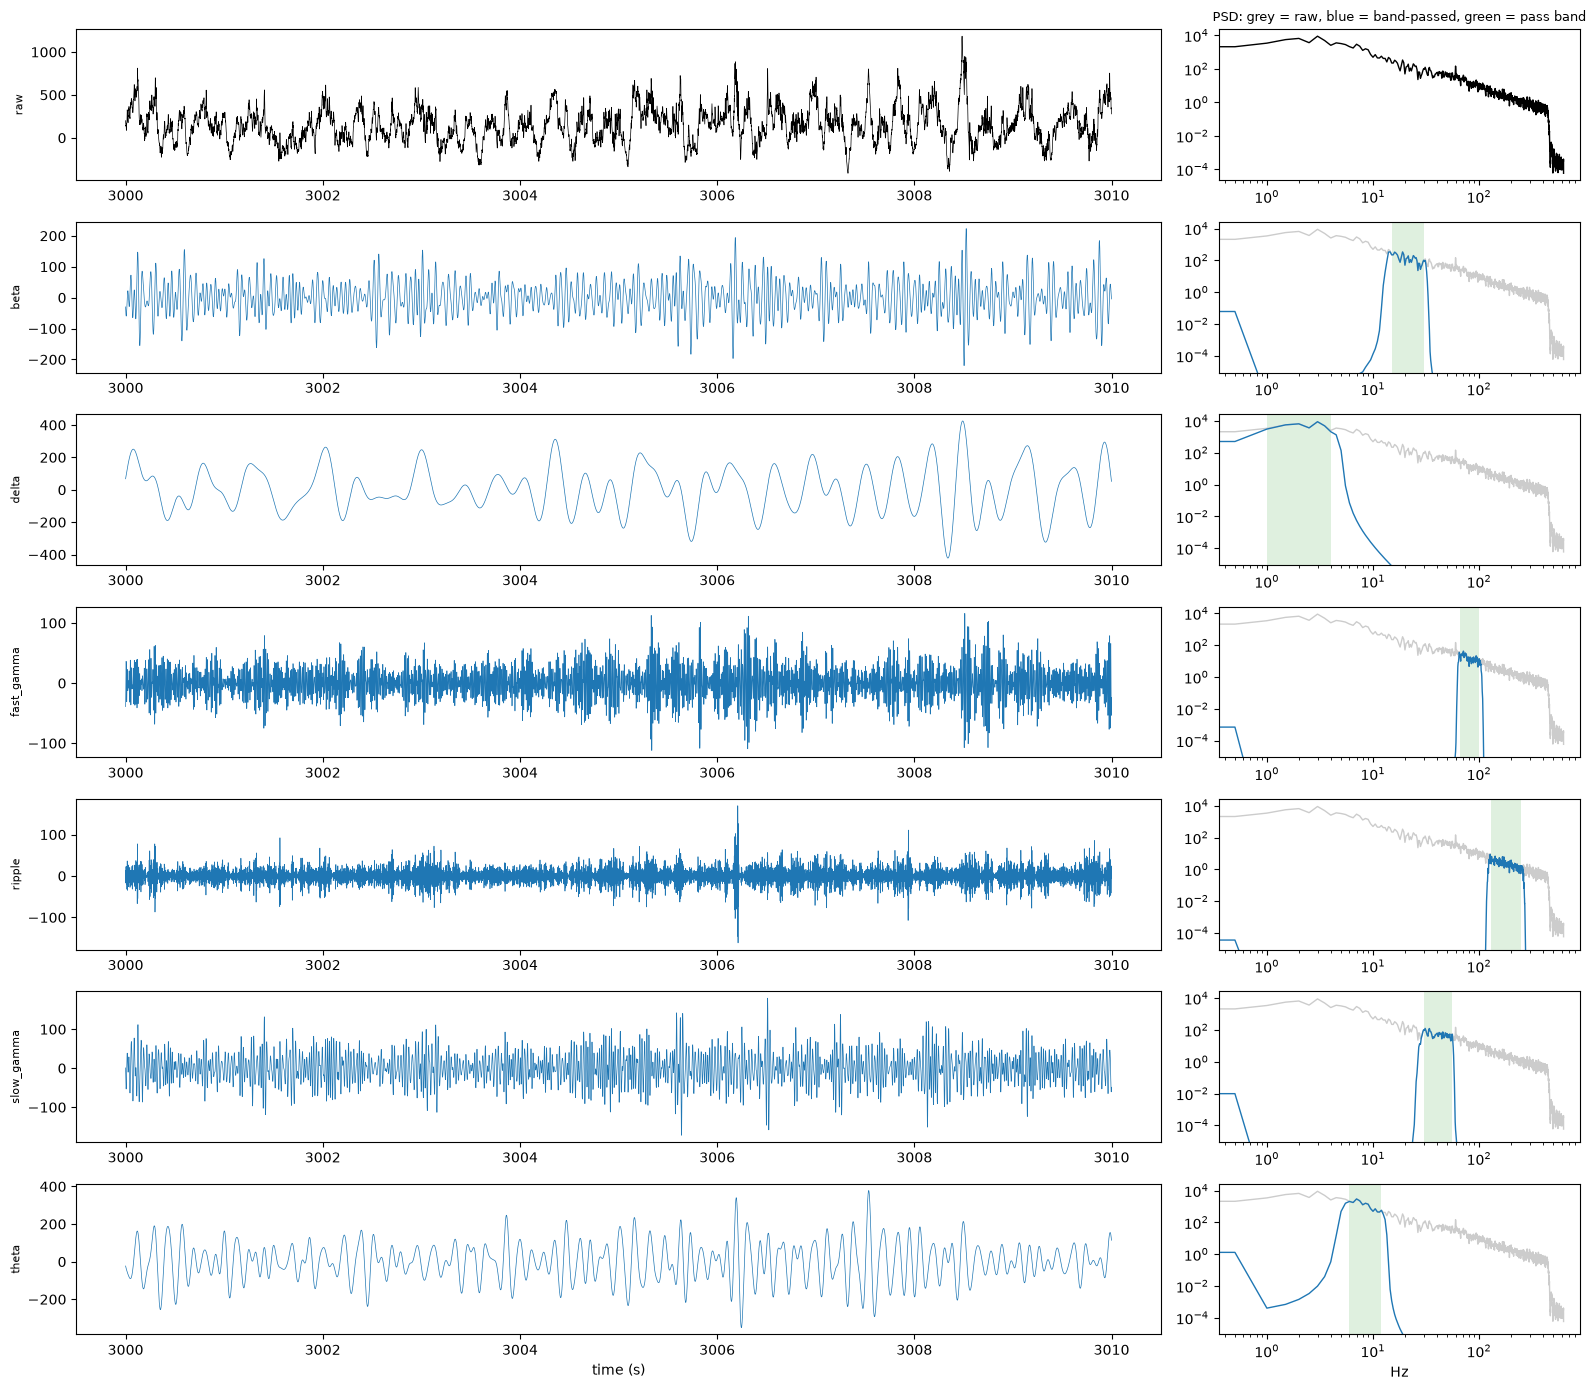

In [25]:
# ============ load the saved filters, find the live stretches of LFP, filter each on its own, cut each end by the longest ============
import time
import numpy as np
import scipy.signal as sps
import pynapple as nap
from pathlib import Path
from scipy.fft import next_fast_len

FILTER_DIR  = Path("filters").resolve()
LFP_FILE    = Path("/storage/dandi_downloads/sub-M01/sub-M01_ses-20240313T100000_behavior+ecephys.nwb")
LFP_KEY     = "Best_Ripple_channel_LFP_CA1"
OUT_DIR     = Path("/storage/grassmanian_test/Hp_001695/lfp")
SESSION_KEY = "M01_20240313T100000"
fs          = 1250.0
BIN_MS      = 50.0
DEAD_RUN_S  = 0.1                         # a constant value held this long = no signal

# ---- filters from disk
filters, BAND_DESIGN = {}, {}
for f in sorted(FILTER_DIR.glob("fir_*_%.0fHz.npz" % fs)):
    with np.load(f) as z:
        name = f.stem[len("fir_"):-len("_%.0fHz" % fs)]
        filters[name] = z["taps"].astype(float)
        BAND_DESIGN[name] = (float(z["l_freq"]), float(z["h_freq"]), float(z["l_trans"]), float(z["h_trans"]))
if not filters:
    raise FileNotFoundError("no fir_*_%.0fHz.npz in %s" % (fs, FILTER_DIR))
longest_band = max(filters, key=lambda b: len(filters[b]))
n_edge = len(filters[longest_band]) // 2
print("filters:", {b: len(t) for b, t in filters.items()}, "| longest %s -> %.1f s cut from each end of every live stretch"
      % (longest_band, n_edge / fs))

# ---- the recording and its live stretches
x_lfp = np.asarray(nap.load_file(str(LFP_FILE))[LFP_KEY].values, dtype=float).reshape(-1)
t_lfp = np.arange(len(x_lfp)) / fs
n = len(x_lfp)
change = np.flatnonzero(np.diff(x_lfp) != 0) + 1                   # runs of identical samples
run_start, run_stop = np.r_[0, change], np.r_[change, n]
dead = np.zeros(n, dtype=bool)
for s, e in zip(run_start, run_stop):
    if e - s >= DEAD_RUN_S * fs:
        dead[s:e] = True
d = np.diff(np.r_[0, (~dead).astype(np.int8), 0])
seg_start, seg_stop = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
long_enough = (seg_stop - seg_start) >= 2 * n_edge + 2 * fs          # at least 2 s of signal left after the cut
print("LFP: %.1f s, %.1f%% live, %d live stretches, %d usable after the cut (dropping %d short ones)"
      % (t_lfp[-1], 100 * (~dead).mean(), len(seg_start), long_enough.sum(), (~long_enough).sum()))

# ---- bins (full length) and the power per band, NaN outside the trusted parts of live stretches
bin_s = BIN_MS / 1000.0
bin_idx = np.floor(t_lfp / bin_s).astype(np.int64)
n_bins = int(bin_idx.max()) + 1
n_per_bin = np.bincount(bin_idx, minlength=n_bins).astype(float)
t_center = (np.arange(n_bins) + 0.5) * bin_s
powers = {name: np.full(n_bins, np.nan, dtype=np.float32) for name in filters}
trusted = np.zeros(n, dtype=bool)

t_all = time.time()
for a, b in zip(seg_start[long_enough], seg_stop[long_enough]):
    xs = x_lfp[a:b]
    nfft = next_fast_len(len(xs))
    lo, hi = a + n_edge, b - n_edge                                  # trusted samples of this stretch
    trusted[lo:hi] = True
    bins = bin_idx[lo:hi] - bin_idx[lo]
    cnt = np.bincount(bins)
    full = cnt >= 0.9 * fs * bin_s                                   # only bins (nearly) fully inside the trusted part
    for name, taps in filters.items():
        xf = sps.oaconvolve(xs, taps, mode="same")
        env2 = np.abs(sps.hilbert(xf, N=nfft)[:len(xs)]) ** 2
        p = np.bincount(bins, weights=env2[lo - a:hi - a], minlength=len(cnt)) / np.maximum(cnt, 1)
        powers[name][bin_idx[lo] + np.flatnonzero(full)] = p[full]
print("done in %.1fs | trusted signal %.1f min | bins with power: %d of %d"
      % (time.time() - t_all, trusted.sum() / fs / 60, int(np.isfinite(powers[longest_band]).sum()), n_bins))
for name in filters:
    print("%-11s median power %.3g" % (name, np.nanmedian(powers[name])))
# ============ filter check on 10 s of real signal ============
T_CHECK = 3000.0                                   # inside a live stretch (2140-4870 s)
a = int(T_CHECK * fs); b = a + int(10 * fs)
pad = max(len(t) for t in filters.values()) // 2   # filter with context on both sides, then crop
xs = x_lfp[a - pad:b + pad]
tt = t_lfp[a:b]
print("raw 10 s at %.0f s: std %.3g, %d unique values" % (T_CHECK, x_lfp[a:b].std(), len(np.unique(x_lfp[a:b]))))

fig, axes = plt.subplots(len(filters) + 1, 2, figsize=(16, 2.0 * (len(filters) + 1)),
                         gridspec_kw={"width_ratios": [3, 1]})
axes[0, 0].plot(tt, x_lfp[a:b], lw=0.5, color="k"); axes[0, 0].set_ylabel("raw", fontsize=8)
f_raw, p_raw = sps.welch(x_lfp[a:b], fs=fs, nperseg=int(2 * fs))
axes[0, 1].loglog(f_raw, p_raw, color="k", lw=1)
for ax, (name, taps) in zip(axes[1:], filters.items()):
    xf = sps.oaconvolve(xs, taps, mode="same")[pad:pad + (b - a)]
    ax[0].plot(tt, xf, lw=0.5, color="tab:blue"); ax[0].set_ylabel(name, fontsize=8)
    f_b, p_b = sps.welch(xf, fs=fs, nperseg=int(2 * fs))
    ax[1].loglog(f_raw, p_raw, color="0.8", lw=1); ax[1].loglog(f_b, p_b, color="tab:blue", lw=1)
    ax[1].axvspan(BAND_DESIGN[name][0], BAND_DESIGN[name][1], color="tab:green", alpha=0.15, lw=0)
    ax[1].set_ylim(p_raw.max() * 1e-9, p_raw.max() * 3)
axes[-1, 0].set_xlabel("time (s)"); axes[-1, 1].set_xlabel("Hz")
axes[0, 1].set_title("PSD: grey = raw, blue = band-passed, green = pass band", fontsize=9)
plt.tight_layout(); plt.show()


In [26]:
raw = np.asarray(nap.load_file(str(LFP_FILE))[LFP_KEY].values).reshape(-1)
for t in (1000, 3000, 5500, 7000, 9500):
    seg = raw[int(t * 1250):int(t * 1250) + 2500]
    print("t=%5d s: std %.4g | unique values %d | %s" % (t, seg.std(), len(np.unique(seg)), seg[:6]))


t= 1000 s: std 0 | unique values 1 | [145 145 145 145 145 145]
t= 3000 s: std 180.4 | unique values 733 | [200 170 157 148 139 146]
t= 5500 s: std 0 | unique values 1 | [145 145 145 145 145 145]
t= 7000 s: std 0 | unique values 1 | [145 145 145 145 145 145]
t= 9500 s: std 211.7 | unique values 804 | [185 160 151 207 243 227]


In [28]:
# ============ save the checked filters: one file per band, plus an index ============
import json
FILTER_DIR = Path("filters").resolve()
FILTER_DIR.mkdir(parents=True, exist_ok=True)

written = []
for name, taps in filters.items():
    lo, hi, lt, ht = BAND_DESIGN[name]
    out = FILTER_DIR / ("fir_%s_%.0fHz.npz" % (name, fs))
    np.savez(out, taps=taps, l_freq=lo, h_freq=hi, l_trans=lt, h_trans=ht, fs=fs,
             n_taps=len(taps), design=json.dumps(FIR), lfp_key=LFP_KEY)
    written.append(out.name)
    print("wrote %s | %d taps (%.2f s), pass %g-%g Hz, stop edges %g | %g Hz" % (out.name, len(taps), len(taps) / fs, lo, hi, lo - lt, hi + ht))

longest = max(filters, key=lambda k: len(filters[k]))
(FILTER_DIR / "bands.json").write_text(json.dumps(
    {"fs": fs, "lfp_key": LFP_KEY, "fir": FIR, "files": written,
     "bands": {k: {"lo": v[0], "hi": v[1], "l_trans": v[2], "h_trans": v[3], "n_taps": len(filters[k])}
               for k, v in BAND_DESIGN.items() if k in filters},
     "longest_filter": longest, "cut_s_each_end": (len(filters[longest]) // 2) / fs}, indent=2))
print("index: %s | longest %s -> cut %.1f s from each end of every live stretch when applying"
      % (FILTER_DIR / "bands.json", longest, (len(filters[longest]) // 2) / fs))


wrote fir_beta_1250Hz.npz | 2085 taps (1.67 s), pass 15-30 Hz, stop edges 12 | 34 Hz
wrote fir_delta_1250Hz.npz | 12501 taps (10.00 s), pass 1-4 Hz, stop edges 0.5 | 5 Hz
wrote fir_fast_gamma_1250Hz.npz | 1251 taps (1.00 s), pass 66-100 Hz, stop edges 61 | 110 Hz
wrote fir_ripple_1250Hz.npz | 417 taps (0.33 s), pass 130-250 Hz, stop edges 115 | 275 Hz
wrote fir_slow_gamma_1250Hz.npz | 1563 taps (1.25 s), pass 30-55 Hz, stop edges 25 | 59 Hz
wrote fir_theta_1250Hz.npz | 4167 taps (3.33 s), pass 6-12 Hz, stop edges 4.5 | 14 Hz
index: /notebooks/CumulantDynamicsGuiltByAssociation/Hydrangea_demo/Validating_Hybrid_Dynamics/RealData_Grassmanian_Tests/CA1data/lfp_filters/filters/bands.json | longest delta -> cut 5.0 s from each end of every live stretch when applying
